**Olist Delivery Performance: 01 Exploratory Data Analysis**

In [3]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
from features import add_distance, add_labels, connect, load_delivered, zip_centroids

IMG = ROOT / "images"
IMG.mkdir(exist_ok=True)
sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 50)

In [4]:
conn = connect()
df = add_labels(load_delivered(conn))
print(df.shape)
df.head()

(96470, 33)


,order_id,customer_state,customer_city,customer_zip_code_prefix,seller_id,seller_state,seller_city,seller_zip_code_prefix,product_category,order_purchase_timestamp,purchase_month,item_count,order_value,freight_value,total_weight_g,total_volume_cm3,seller_count,review_score,approval_days,seller_handling_days,carrier_transit_days,total_days,estimated_lead_days,days_vs_estimate,is_late,missed_seller_deadline,same_state,customer_state_name,seller_state_name,customer_region,seller_region,delivery_status,delay_bucket
0,00010242fe8c5a6d1ba2dd792cb16214,RJ,campos dos goytacazes,28013,48436dade18ac8b2bce089ec2a041202,SP,volta redonda,27277,cool_stuff,2017-09-13 08:59:02,2017-09,1,58.90,13.29,650.0,3528.0,1,5.0,0.03,6.37,1.21,7.61,15.63,-9.0,0,1,0,Rio de Janeiro,São Paulo,Southeast,Southeast,On time,2. Early 1-9 days
1,00018f77f2f0320c557190d7a144bdd3,SP,santa fe do sul,15775,dd7ddc04e1b6c2c614352b383efe2d36,SP,sao paulo,3471,pet_shop,2017-04-26 10:53:06,2017-04,1,239.90,19.93,30000.0,60000.0,1,4.0,0.01,8.15,8.06,16.22,18.55,-3.0,0,1,1,São Paulo,São Paulo,Southeast,Southeast,On time,2. Early 1-9 days
2,000229ec398224ef6ca0657da4fc703e,MG,para de minas,35661,5b51032eddd242adc84c38acab88f23d,MG,borda da mata,37564,furniture_decor,2018-01-14 14:33:31,2018-01,1,199.00,17.87,3050.0,14157.0,1,5.0,0.01,1.91,6.03,7.95,21.39,-14.0,0,0,1,Minas Gerais,Minas Gerais,Southeast,Southeast,On time,1. Early 10+ days
3,00024acbcdf0a6daa1e931b038114c75,SP,atibaia,12952,9d7a1d34a5052409006425275ba1c2b4,SP,franca,14403,perfumery,2018-08-08 10:00:35,2018-08,1,12.99,12.79,200.0,2400.0,1,4.0,0.01,2.14,4.00,6.15,11.58,-6.0,0,0,1,São Paulo,São Paulo,Southeast,Southeast,On time,2. Early 1-9 days
4,00042b26cf59d7ce69dfabb4e55b4fd9,SP,varzea paulista,13226,df560393f3a51e74553ab94004ba5c87,PR,loanda,87900,garden_tools,2017-02-04 13:57:51,2017-02,1,199.90,18.14,3750.0,42000.0,1,5.0,0.01,11.82,13.29,25.11,40.42,-16.0,0,1,0,São Paulo,Paraná,Southeast,South,On time,1. Early 10+ days


**1. Data quality checks**

Nulls in the stage columns come from missing timestamps. Negative durations are timestamp errors in the source data (for example, carrier pickup logged before payment approval).

In [5]:
stage_cols = ["approval_days", "seller_handling_days", "carrier_transit_days", "total_days"]
quality = pd.DataFrame({
    "nulls": df[stage_cols].isna().sum(),
    "negative": (df[stage_cols] < 0).sum(),
    "over_60_days": (df[stage_cols] > 60).sum(),
})
quality["negative_pct"] = (100 * quality["negative"] / len(df)).round(2)
quality

,nulls,negative,over_60_days,negative_pct
approval_days,14,0,0,0.00
seller_handling_days,15,1325,6,1.37
carrier_transit_days,1,23,225,0.02
total_days,0,0,306,0.00


In [6]:
df[stage_cols + ["estimated_lead_days", "days_vs_estimate"]].describe().round(2)

,approval_days,seller_handling_days,carrier_transit_days,total_days,estimated_lead_days,days_vs_estimate
count,96456.00,96455.00,96469.00,96470.00,96470.00,96470.00
mean,0.43,2.80,9.33,12.56,23.74,-11.88
std,0.86,3.54,8.76,9.55,8.76,10.18
min,0.00,-171.22,-16.10,0.53,2.01,-147.00
25%,0.01,0.87,4.10,6.77,18.33,-17.00
50%,0.01,1.82,7.10,10.22,23.23,-12.00
75%,0.60,3.57,12.03,15.72,28.41,-7.00
max,30.89,125.76,205.19,209.63,155.14,188.00


**2. Headline numbers**

In [7]:
summary = {
    "delivered_orders": len(df),
    "on_time_rate_pct": round(100 * (1 - df["is_late"].mean()), 2),
    "late_rate_pct": round(100 * df["is_late"].mean(), 2),
    "avg_delivery_days": round(df["total_days"].mean(), 2),
    "median_delivery_days": round(df["total_days"].median(), 2),
    "avg_promised_days": round(df["estimated_lead_days"].mean(), 2),
    "avg_days_late_when_late": round(df.loc[df["is_late"] == 1, "days_vs_estimate"].mean(), 2),
    "customer_states": df["customer_state"].nunique(),
}
pd.Series(summary)

delivered_orders           96470.00
on_time_rate_pct              93.23
late_rate_pct                  6.77
avg_delivery_days             12.56
median_delivery_days          10.22
avg_promised_days             23.74
avg_days_late_when_late       10.62
customer_states               27.00
dtype: float64

**3. Actual vs promised delivery time**

If promised days sit far to the right of actual days, Olist pads its estimates, which hides operational problems.

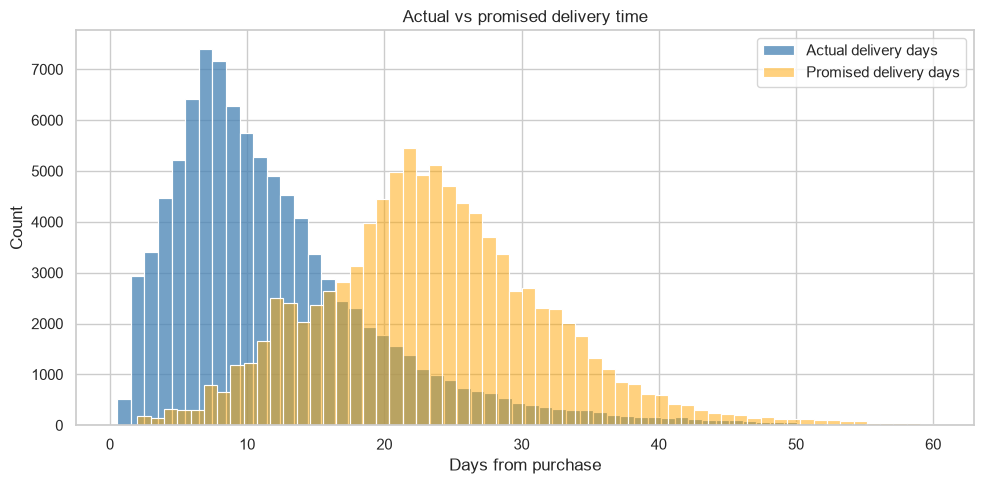

In [8]:
fig, ax = plt.subplots(figsize=(10, 5))
clip = df[(df["total_days"].between(0, 60)) & (df["estimated_lead_days"].between(0, 60))]
sns.histplot(clip["total_days"], bins=60, color="steelblue", label="Actual delivery days", ax=ax)
sns.histplot(clip["estimated_lead_days"], bins=60, color="orange", alpha=0.5, label="Promised delivery days", ax=ax)
ax.set_title("Actual vs promised delivery time")
ax.set_xlabel("Days from purchase")
ax.legend()
plt.tight_layout()
plt.savefig(IMG / "actual_vs_promised.png", dpi=150)
plt.show()

**4. Which stage grows when an order is late?**

                 approval_days  seller_handling_days  carrier_transit_days
delivery_status                                                           
Late                       0.5                  5.57                 27.88
On time                    0.4                  2.65                  8.00

Extra days in late orders by stage:
                      extra_days  share_of_extra_pct
approval_days               0.11                 0.5
seller_handling_days        2.92                12.8
carrier_transit_days       19.88                86.8


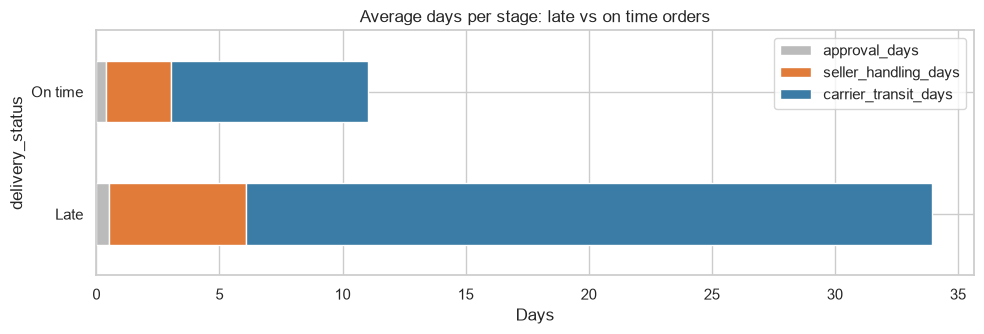

In [9]:
clean = df[(df["seller_handling_days"] >= 0) & (df["carrier_transit_days"] >= 0)]
stage_means = clean.groupby("delivery_status")[["approval_days", "seller_handling_days", "carrier_transit_days"]].mean()
print(stage_means.round(2))

extra = stage_means.loc["Late"] - stage_means.loc["On time"]
share = (100 * extra / extra.sum()).round(1)
print("\nExtra days in late orders by stage:")
print(pd.DataFrame({"extra_days": extra.round(2), "share_of_extra_pct": share}))

stage_means.plot(kind="barh", stacked=True, figsize=(10, 3.5), color=["#bbbbbb", "#e07b39", "#3a7ca5"])
plt.title("Average days per stage: late vs on time orders")
plt.xlabel("Days")
plt.tight_layout()
plt.savefig(IMG / "stage_breakdown.png", dpi=150)
plt.show()

**5. Late rate by customer state**

,orders,late_rate,avg_days,stdev_days
customer_state,,,,
AL,397,0.214,24.544,11.483
MA,717,0.174,21.573,11.355
SE,335,0.152,21.520,16.760
PI,476,0.139,19.457,14.719
CE,1279,0.138,21.267,13.125
RR,41,0.122,29.387,27.743
BA,3256,0.122,19.335,11.694
RJ,12350,0.121,15.309,11.522
PA,946,0.112,23.773,13.154


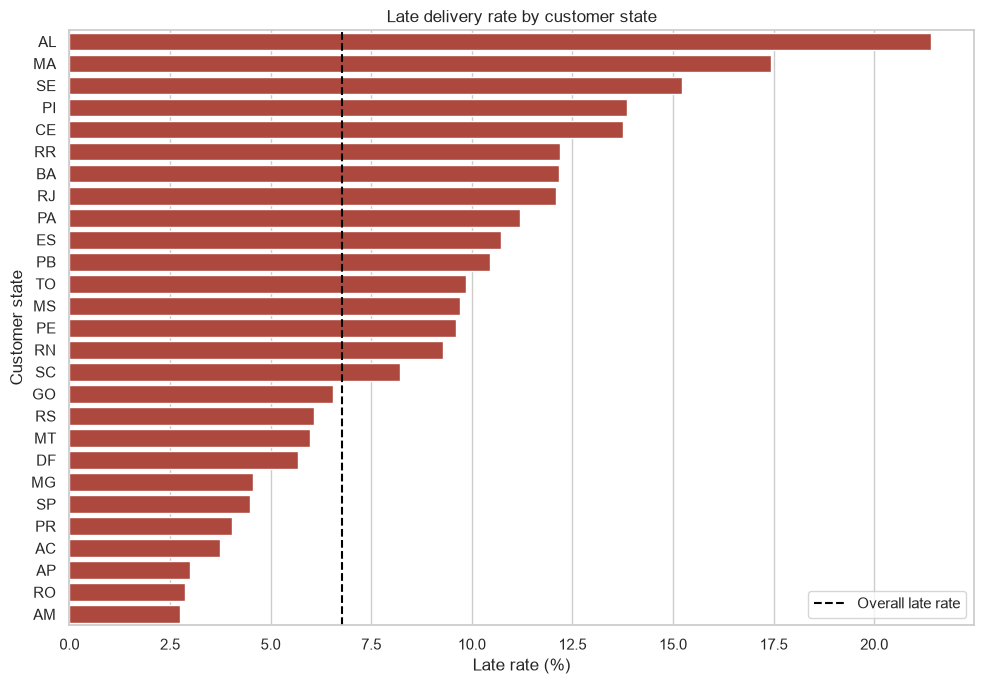

In [10]:
by_state = (df.groupby("customer_state")
            .agg(orders=("order_id", "count"), late_rate=("is_late", "mean"),
                 avg_days=("total_days", "mean"), stdev_days=("total_days", "std"))
            .sort_values("late_rate", ascending=False))
display(by_state.round(3))

fig, ax = plt.subplots(figsize=(10, 7))
sns.barplot(x=by_state["late_rate"] * 100, y=by_state.index, color="#c0392b", ax=ax)
ax.axvline(df["is_late"].mean() * 100, color="black", linestyle="--", label="Overall late rate")
ax.set_xlabel("Late rate (%)")
ax.set_ylabel("Customer state")
ax.set_title("Late delivery rate by customer state")
ax.legend()
plt.tight_layout()
plt.savefig(IMG / "late_rate_by_state.png", dpi=150)
plt.show()

**6. Late rate by region**

In [11]:
df.groupby("customer_region").agg(
    orders=("order_id", "count"),
    late_rate_pct=("is_late", lambda s: round(100 * s.mean(), 2)),
    avg_days=("total_days", "mean"),
).sort_values("late_rate_pct", ascending=False).round(2)

,orders,late_rate_pct,avg_days
customer_region,,,
Northeast,9044,12.72,20.01
North,1796,8.57,22.59
Central-West,5624,6.53,15.02
Southeast,66193,6.12,10.75
South,13813,5.90,14.03


**7. Monthly trend**

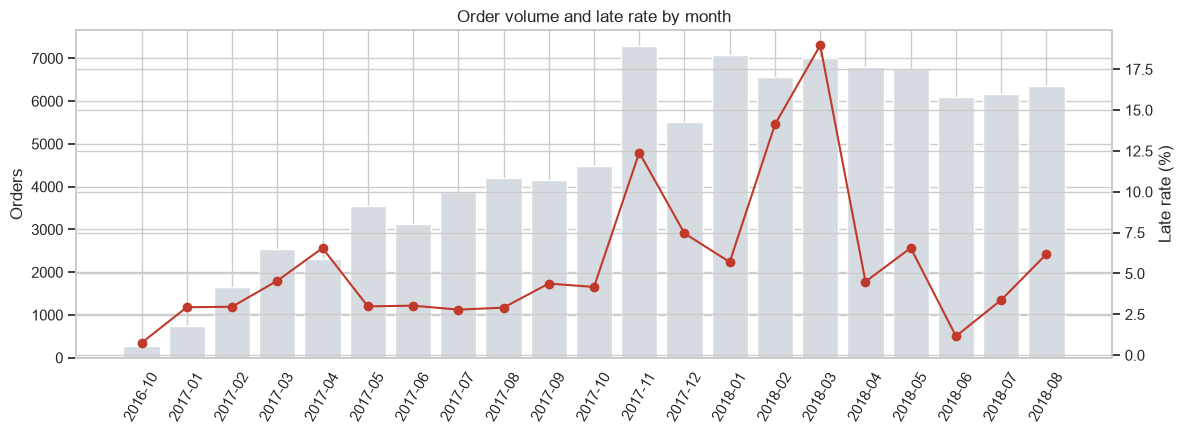

In [12]:
monthly = df.groupby("purchase_month").agg(orders=("order_id", "count"), late_rate=("is_late", "mean"))
monthly = monthly[monthly["orders"] >= 100]

fig, ax1 = plt.subplots(figsize=(12, 4.5))
ax1.bar(monthly.index, monthly["orders"], color="#d5dbe0", label="Orders")
ax1.set_ylabel("Orders")
ax2 = ax1.twinx()
ax2.plot(monthly.index, monthly["late_rate"] * 100, color="#c0392b", marker="o", label="Late rate %")
ax2.set_ylabel("Late rate (%)")
ax1.tick_params(axis="x", rotation=60)
plt.title("Order volume and late rate by month")
plt.tight_layout()
plt.savefig(IMG / "monthly_trend.png", dpi=150)
plt.show()

**8. Customer impact: review score vs delay**

,orders,avg_review,low_review_pct
delay_bucket,,,
1. Early 10+ days,61523,4.32,8.86
2. Early 1-9 days,26640,4.23,9.95
3. On estimate day,1280,4.04,12.27
4. Late 1-3 days,1852,3.29,32.18
5. Late 4-7 days,1748,2.11,67.56
6. Late 8+ days,2781,1.70,79.18


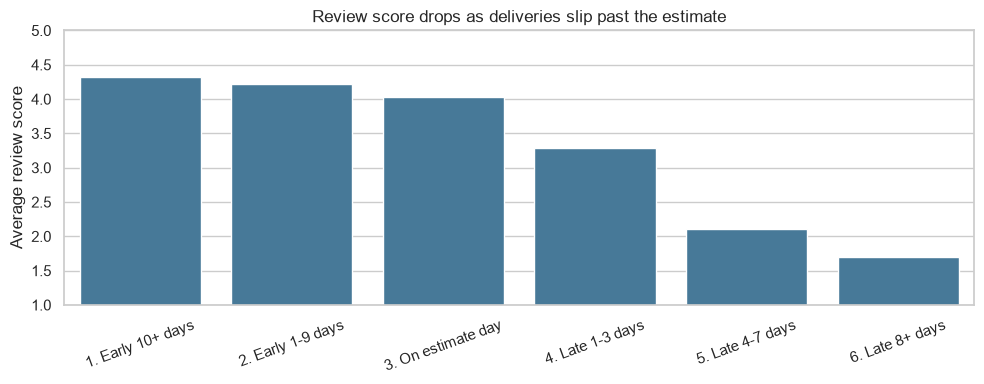

Avg review on time: 4.29 | late: 2.27 | gap: 2.02 points


In [13]:
review = (df.dropna(subset=["review_score"])
          .groupby("delay_bucket")
          .agg(orders=("order_id", "count"), avg_review=("review_score", "mean"),
               low_review_pct=("review_score", lambda s: 100 * (s <= 2).mean())))
display(review.round(2))

fig, ax = plt.subplots(figsize=(10, 4))
sns.barplot(x=review.index, y=review["avg_review"], color="#3a7ca5", ax=ax)
ax.set_ylim(1, 5)
ax.set_ylabel("Average review score")
ax.set_xlabel("")
ax.set_title("Review score drops as deliveries slip past the estimate")
plt.xticks(rotation=20)
plt.tight_layout()
plt.savefig(IMG / "review_vs_delay.png", dpi=150)
plt.show()

on_time_review = df.loc[df["is_late"] == 0, "review_score"].mean()
late_review = df.loc[df["is_late"] == 1, "review_score"].mean()
print(f"Avg review on time: {on_time_review:.2f} | late: {late_review:.2f} | gap: {on_time_review - late_review:.2f} points")

In [14]:
conn.close()